<h1 align = "center">  Life Satisfaction Prediction using GDP per Capita </h1>



**Assignment Note**

This assignment is not intended to be a full project. It serves as a follow up to reinforce the concepts we have covered in lecture so
far. More comprehensive analyses and detailed projects will be introduced as we progress further into the course

---

### 🤔📚Learning Objectives


- Load and visualize real-world data
- Train and compare regression models using Scikit-Learn.
- Interpret model outputs and discuss generalization.


---

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor


## Part 1: Data Exploration and Visualization (20 marks)


**Q1 (5 marks)** Load the dataset `lifesat.csv` and display the first 5 rows.


In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("lifesat.csv")
df.head()

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


**Q2 (5 marks)** Print basic `info` and `summary statistics` .


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country               27 non-null     str    
 1   GDP per capita (USD)  27 non-null     float64
 2   Life satisfaction     27 non-null     float64
dtypes: float64(2), str(1)
memory usage: 983.0 bytes


In [9]:
print(df.describe())

       GDP per capita (USD)  Life satisfaction
count             27.000000          27.000000
mean           41564.521771           6.566667
std             9631.452319           0.765607
min            26456.387938           5.400000
25%            33938.289305           5.900000
50%            41627.129269           6.800000
75%            49690.580269           7.300000
max            60235.728492           7.600000


**Q3 (10 marks)** Display a scatter plot for `GDP per capita` vs `Life Satisfaction` . Add labels, title, and discuss the observed
relationship.


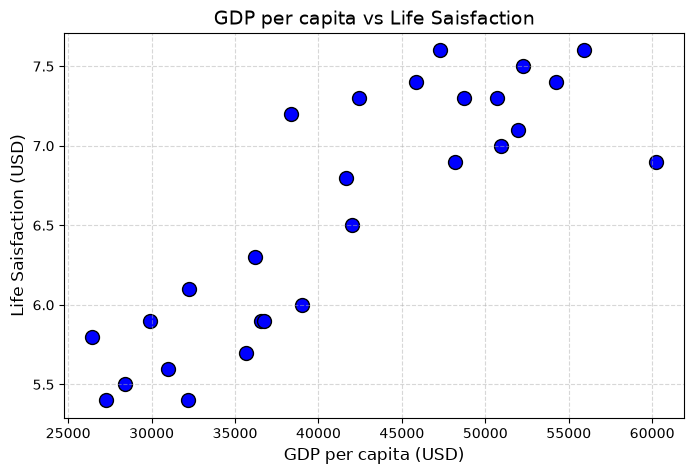

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df['GDP per capita (USD)'],df['Life satisfaction'],color = 'blue',edgecolors = 'black',s=100)
plt.title('GDP per capita vs Life Saisfaction',fontsize=14)
plt.xlabel('GDP per capita (USD)',fontsize=12)
plt.ylabel('Life Saisfaction (USD)',fontsize=12)

plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

**Discuss the observed relationship:**

There is a positive, roughly linear connection between GDP per capita and life satisfaction—countries with higher GDP also exhibit higher levels of life satisfaction. However, this relationship is not strict; for instance, despite the USA having a high GDP, life satisfaction is lower than expected, indicating that GDP is not the sole determining factor.

## Part 2: Linear Regression Model (30 marks)


**Q4 (5 marks)** Extract input (X) and target (y). Print their shapes.

In [13]:
X = df[['GDP per capita (USD)']]
y = df['Life satisfaction']

print(X.shape)
print(y.shape)

(27, 1)
(27,)


**Q5 (10 marks)** Train a Linear Regression model & Display coefficient and intercept.

In [14]:
# To instantiate the model, you need to use LinearRegression()
# use fit function to train the model
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X,y)

print("Coefficient (slope):", lin_reg.coef_[0])
print("Intercept:", lin_reg.intercept_)

Coefficient (slope): 6.778899694341222e-05
Intercept: 3.7490494273769093


**Q6 (10 marks)** Plot the predicted regression line from the model along with a scatter plot of the data.

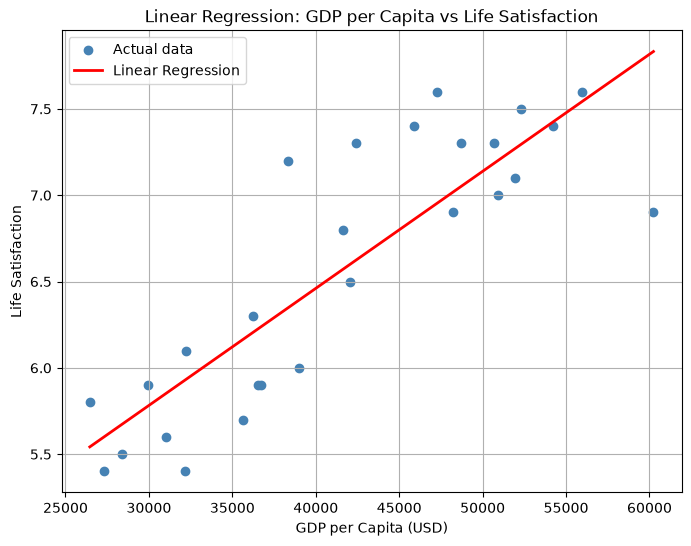

In [17]:
import numpy as np
lin_reg.fit(X.values,y)
X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = lin_reg.predict(X_line)

plt.figure(figsize=(8,6))
plt.scatter(X, y, color='steelblue', label='Actual data')
plt.plot(X_line, y_line, color='red', linewidth=2, label='Linear Regression')
plt.xlabel('GDP per Capita (USD)')
plt.ylabel('Life Satisfaction')
plt.title('Linear Regression: GDP per Capita vs Life Satisfaction')
plt.legend()
plt.grid(True)
plt.show()

**Q7 (5 marks)** Predict Life Satisfaction for GDP = 37,655.2 USD. Comment on result.

In [18]:
gdp_new = [[37655.2]]
lin_reg.fit(X.values,y)
pred_lin = lin_reg.predict(gdp_new)
print(f"Predicted Life Satisfaction for GDP = $37,655.2: {pred_lin[0]:.2f}")

Predicted Life Satisfaction for GDP = $37,655.2: 6.30


## Part 3: K-Nearest Neighbors Regression (25 marks)

**Q8 (5 marks)** Train a KNeighborsRegressor (n_neighbors=3).


In [19]:
# you have done this already in the IRIS Flower example 
from sklearn.neighbors import KNeighborsRegressor

knn_reg = KNeighborsRegressor(n_neighbors=3)
knn_reg.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


**Q9 (10 marks)**

- Predict Life Satisfaction for GDP = 37,655.2 USD
- and compare with Linear Regression.


In [32]:
gdp_new = pd.DataFrame([[37655.2]],columns=X.columns)
pred_knn3 = knn_reg.predict(gdp_new)
print(f"KNN (k=3) prediction for GDP = $37,655.2: {pred_knn3[0]:.2f}")
print(f"Linear Regression prediction:{pred_lin[0]:.2f}")
print(f"Difference:{abs(pred_knn3[0] - pred_lin[0]):.2f}")

KNN (k=3) prediction for GDP = $37,655.2: 6.33
Linear Regression prediction:6.30
Difference:0.03


**Q10 (10 marks)**
- Use n_neighbors 1, 3, 5, and 10 and print the predicted values of life satisfaction in Q10.
- Plot the results using a line plot.

In [31]:
n_values = [1, 3, 5, 10]
pred_list = []

for n in n_values:
    knn = KNeighborsRegressor(n_neighbors=n)
    knn.fit(X, y)
    gdp_new_df = pd.DataFrame(gdp_new,columns=X.columns)
    pred = knn.predict(gdp_new_df)[0]
    pred_list.append(pred)
    print(f"n_neighbors = {n:2d} -> Predicted Life Satisfaction = {pred:.2f}")

n_neighbors =  1 -> Predicted Life Satisfaction = 7.20
n_neighbors =  3 -> Predicted Life Satisfaction = 6.33
n_neighbors =  5 -> Predicted Life Satisfaction = 6.26
n_neighbors = 10 -> Predicted Life Satisfaction = 6.37


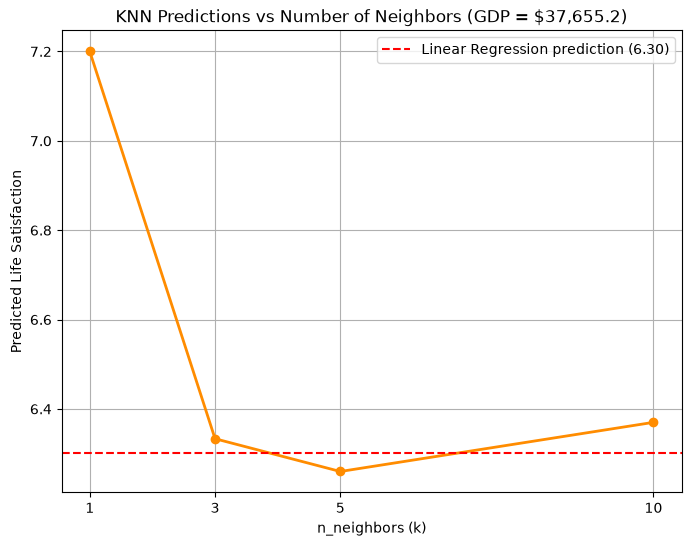

In [30]:
# Plot n vs pred_list
plt.figure(figsize=(8,6))
plt.plot(n_values, pred_list, marker='o', color='darkorange', linewidth=2)
plt.axhline(y=pred_lin[0], color='red', linestyle='--', label=f'Linear Regression prediction ({pred_lin[0]:.2f})')
plt.xlabel('n_neighbors (k)')
plt.ylabel('Predicted Life Satisfaction')
plt.title('KNN Predictions vs Number of Neighbors (GDP = $37,655.2)')
plt.xticks(n_values)
plt.legend()
plt.grid(True)
plt.show()

___